# 01 · Análise exploratória: por que os clientes cancelam?

**Pergunta de negócio:** numa operadora de telecom, quais clientes têm mais chance de cancelar e quais fatores explicam isso?

**Dados:** *Telco Customer Churn* (IBM), base pública com 7.043 clientes, 19 variáveis e a coluna `Churn` (cancelou no último mês).

Neste notebook eu entendo a base antes de qualquer modelo: qualidade dos dados, taxa de churn e os fatores que mais se relacionam com o cancelamento.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from churn.data import load_clean, load_raw

pd.set_option("display.max_columns", 30)

## 1. Primeira olhada nos dados brutos

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.dtypes.value_counts()

str        18
int64       2
float64     1
Name: count, dtype: int64

`TotalCharges` deveria ser número, mas veio como texto. Vamos ver por quê:

In [4]:
em_branco = raw[raw["TotalCharges"].str.strip() == ""]
print(f"{len(em_branco)} linhas com TotalCharges em branco")
em_branco[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

11 linhas com TotalCharges em branco


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Todas as 11 linhas têm `tenure = 0`: são clientes recém-chegados, que ainda não pagaram nenhuma fatura. O valor correto é **0**, não um valor médio. A função `clean()` em `src/churn/data.py` faz essa correção, transforma `SeniorCitizen` em categoria e `Churn` em 0/1.

In [5]:
df = load_clean()
print(df.shape)
print("Nulos restantes:", int(df.isna().sum().sum()))
print("IDs duplicados:", int(df["customerID"].duplicated().sum()))

(7043, 21)
Nulos restantes: 0
IDs duplicados: 0


## 2. Quanto churn existe?

In [6]:
taxa = df["Churn"].mean()
print(f"Taxa de churn: {taxa:.1%} ({df['Churn'].sum()} de {len(df)} clientes)")

Taxa de churn: 26.5% (1869 de 7043 clientes)


**26,5%**: cerca de 1 em cada 4 clientes. A base é **desbalanceada**: um modelo que chuta "ninguém cancela" já acerta 73,5%. Por isso a acurácia não serve como métrica principal; vou usar ROC-AUC, recall e precisão.

## 3. Variáveis numéricas

In [7]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median().rename(index={0: "Ficou", 1: "Cancelou"})

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Ficou,38.0,64.425,1679.525
Cancelou,10.0,79.650,703.550


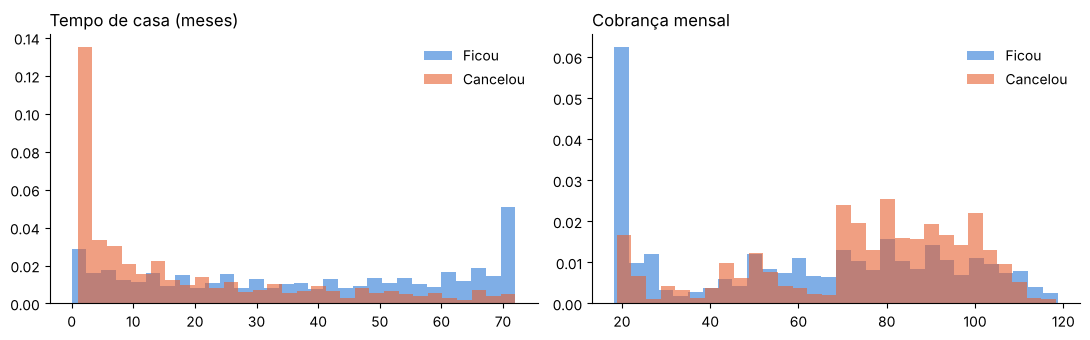

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col, titulo in zip(axes, ["tenure", "MonthlyCharges"], ["Tempo de casa (meses)", "Cobrança mensal"]):
    for churn, cor, nome in [(0, "#2a78d6", "Ficou"), (1, "#e6602f", "Cancelou")]:
        ax.hist(df.loc[df["Churn"] == churn, col], bins=30, alpha=0.6, color=cor, label=nome, density=True)
    ax.set_title(titulo, loc="left")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

- Quem cancela tem **pouco tempo de casa**: a mediana é 10 meses, contra 38 de quem fica.
- Quem cancela **paga mais por mês**: a mediana é cerca de R$ 80, contra R$ 64.

`TotalCharges` é quase `tenure × MonthlyCharges`, então carrega pouca informação nova:

In [9]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].corr().round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


## 4. Variáveis categóricas: taxa de churn por grupo

In [10]:
def taxa_por(col):
    return (
        df.groupby(col)["Churn"].agg(taxa="mean", clientes="size")
        .sort_values("taxa", ascending=False)
        .style.format({"taxa": "{:.1%}"})
    )

taxa_por("Contract")

,taxa,clientes
Contract,,
Month-to-month,42.7%,3875
One year,11.3%,1473
Two year,2.8%,1695


In [11]:
taxa_por("PaymentMethod")

,taxa,clientes
PaymentMethod,,
Electronic check,45.3%,2365
Mailed check,19.1%,1612
Bank transfer (automatic),16.7%,1544
Credit card (automatic),15.2%,1522


In [12]:
taxa_por("InternetService")

,taxa,clientes
InternetService,,
Fiber optic,41.9%,3096
DSL,19.0%,2421
No,7.4%,1526


In [13]:
taxa_por("TechSupport")

,taxa,clientes
TechSupport,,
No,41.6%,3473
Yes,15.2%,2044
No internet service,7.4%,1526


Para comparar todas as variáveis de uma vez, calculo a **diferença entre o grupo com maior e o com menor taxa** em cada uma:

In [14]:
from churn.features import CATEGORICAL

amplitude = {}
for col in CATEGORICAL:
    taxas = df.groupby(col)["Churn"].mean()
    amplitude[col] = taxas.max() - taxas.min()
pd.Series(amplitude).sort_values(ascending=False).map("{:.1%}".format).to_frame("diferença entre grupos")

,diferença entre grupos
Contract,39.9%
InternetService,34.5%
OnlineSecurity,34.4%
TechSupport,34.2%
OnlineBackup,32.5%
DeviceProtection,31.7%
PaymentMethod,30.0%
StreamingMovies,26.3%
StreamingTV,26.1%
SeniorCitizen,18.1%


## 5. Tempo de casa em faixas

In [15]:
faixas = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
df.groupby(faixas, observed=True)["Churn"].mean().map("{:.1%}".format).to_frame("taxa de churn")

,taxa de churn
tenure,
0–6,52.9%
7–12,35.9%
13–24,28.7%
25–48,20.4%
49–72,9.5%


## Conclusões da exploração

1. **Contrato é o fator mais forte.** Contrato mensal cancela 42,7%; o de 2 anos, 2,8%, cerca de **15 vezes menos**.
2. **Forma de pagamento importa.** Cheque eletrônico cancela 45,3%, cerca de **3 vezes** mais que cartão automático (15,2%).
3. **Quem cancela, cancela cedo.** Nos primeiros 6 meses a taxa passa de 50% e cai para menos de 10% depois de 4 anos.
4. **Fibra óptica e falta de suporte técnico** também aparecem com taxas altas, o que pode indicar preço alto ou serviço com problema.
5. Gênero, e telefone ou não, praticamente **não mudam** a taxa.

**Cuidado:** são correlações, não causas. Contrato mensal não *causa* o cancelamento; quem pretende sair escolhe não se prender. Mesmo assim, para o time de retenção, isso basta para **priorizar quem abordar**.

Próximo passo: o notebook `02_modelagem.ipynb`, que transforma esses padrões em um modelo.